> 🔓 **SOLUTIONS EDITION**: this is the instructor copy with worked solutions and executed outputs. Please attempt every problem in the student notebook first; struggling is where learning happens.

# 📘 Lesson 13: K-Nearest Neighbors Classification
*You are the company you keep: classify by a vote of the most similar examples*

| ⏱️ Time | 🎚️ Level | 🧰 Prerequisites |
|---|---|---|
| ~110 min | 🟢🟡 Beginner → Intermediate | Lessons 07, 09 |

---
## 🎬 The Hook
How does a doctor reason about a patient with unusual symptoms? Often by analogy: *"This reminds me of three previous patients: two had condition A, one had B."* How does your phone recognise your handwriting? By comparing your pen strokes with thousands of labelled examples and asking *"which digit do the closest ones belong to?"*

That is **KNN classification**: no model is trained, no equation is learned. To classify a new point we find its *k* nearest labelled neighbours and let them **vote**. It is a ten-line algorithm that nonetheless reads handwritten digits with about 98.7 % accuracy, and it teaches, better than any other, how *distance*, *scaling* and *class balance* shape every classifier.

---
## 🎯 Learning Objectives
By the end of this notebook you will be able to:

1. Describe KNN classification as a **vote** among the k most similar examples, with probabilities = vote shares.
2. Implement KNN classification **from scratch** and match scikit-learn.
3. See how **k** moves the decision boundary from jagged (k = 1) to rigid (k = n), and choose it by cross-validation.
4. Show why scaling matters and compare distance metrics (Euclidean, Manhattan, cosine).
5. Apply KNN to **handwritten digits** and diagnose its confusions.
6. Explain why KNN is fragile on **imbalanced** data and how thresholds/weights help.
7. State KNN's costs: memory, O(n·p) prediction, the curse of dimensionality.

## 🗺️ Roadmap

- The algorithm
- A hand-worked vote
- From scratch
- k and the decision boundary
- Scaling & distance metrics
- Digits: where KNN shines
- Imbalanced data: where KNN struggles
- Curse of dimensionality & speed
- Cheat-sheet, worked examples, problems, quiz

> 💡 **How to use this notebook:** run cells top to bottom. Read the text *before* you run the code. When you reach a 🧩 **Problem**, try it yourself first, open the hints one at a time, and only then peek at the solutions notebook.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))      # so we can import course_utils.py
from course_utils import *                      # np, pd, plt, check(), data_path(), ...
import numpy as np, pandas as pd, matplotlib.pyplot as plt
%matplotlib inline
RANDOM_STATE = 42
print("Setup complete ✅")
from sklearn.datasets import load_breast_cancer, load_digits, make_moons, make_classification
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score, validation_curve, StratifiedKFold
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score, precision_score, average_precision_score, roc_auc_score

Setup complete ✅


---
## 🧠 1. The algorithm

To classify a query point $x_q$:

1. Compute its distance to every training point.
2. Take the $k$ nearest: the neighbourhood $N_k(x_q)$.
3. **Vote:**

$$\hat P(y=c\mid x_q)=\frac1k\sum_{i\in N_k(x_q)}\mathbb 1[y_i=c]\qquad\hat y=\arg\max_c \hat P(y=c\mid x_q)$$

With `weights='distance'` each neighbour's vote is multiplied by $1/d_i$, so closer neighbours count more.

**Why it works.** The vote share among nearby points is a direct, *non-parametric* estimate of the class probability around $x_q$. As the data grows and $k$ grows (but more slowly than $n$) this converges to the best possible classifier (the *Bayes classifier*); even the crude 1-NN rule has error at most **twice** the Bayes error (Cover & Hart, 1967): a remarkable guarantee for such a simple rule.

> 💡 **Pro tip.**
>
> Use an **odd k** for two classes so a vote can't tie (with 3+ classes ties are still possible; scikit-learn then picks the smallest class label, and distance weighting practically eliminates ties).

---
## ✍️ 2. A hand-worked vote

Seven labelled points (two features) and a query at **(3, 3)**. Classify with k = 3 and k = 5.

,x1,x2,label,distance
1,2.0,2.2,A,1.281
2,4.2,3.9,B,1.500
3,1.3,3.8,A,1.879
4,5.0,3.7,B,2.119
5,3.8,0.9,B,2.247
6,0.5,1.2,A,3.081
7,6.0,6.0,B,4.243


k=3: votes {'A': 2, 'B': 1} -> predict A   P(B) = 0.33
k=5: votes {'B': 3, 'A': 2} -> predict B   P(B) = 0.60


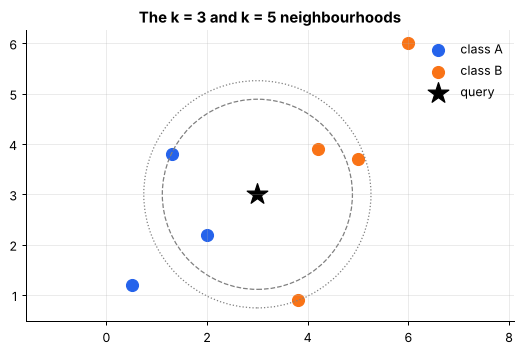

In [2]:
pts = np.array([[2, 2.2], [1.3, 3.8], [0.5, 1.2], [4.2, 3.9], [5, 3.7], [3.8, 0.9], [6, 6]], float); lab = np.array(["A", "A", "A", "B", "B", "B", "B"]); q = np.array([3., 3.])
d = np.sqrt(((pts - q) ** 2).sum(axis=1)); order = np.argsort(d)
table = pd.DataFrame({"x1": pts[order, 0], "x2": pts[order, 1], "label": lab[order], "distance": d[order].round(3)}); table.index += 1; display(table)
for k in [3, 5]:
    votes = pd.Series(lab[order[:k]]).value_counts(); print(f"k={k}: votes {votes.to_dict()} -> predict {votes.idxmax()}   P(B) = {votes.get('B', 0) / k:.2f}")
plt.scatter(*pts[lab == "A"].T, s=90, label="class A"); plt.scatter(*pts[lab == "B"].T, s=90, label="class B"); plt.scatter(*q, marker="*", s=300, color="k", label="query")
for k_, ls in [(3, "--"), (5, ":")]: plt.gca().add_patch(plt.Circle(q, d[order[k_ - 1]] + 0.01, fill=False, ls=ls, color="gray"))
plt.axis("equal"); plt.legend(); plt.title("The k = 3 and k = 5 neighbourhoods"); plt.show()

Note how the answer depends on **k**: the very nearest points tell one story, a slightly wider neighbourhood another. This sensitivity *is* the bias–variance trade-off, as we'll see.

---
## 🔧 3. Build it from scratch

Vectorised distances (the identity $\lVert a-b\rVert^2=\lVert a\rVert^2+\lVert b\rVert^2-2a\!\cdot\!b$ makes Euclidean distance a single matrix product), `argpartition` for the k smallest, then a vote. Optional distance weighting and other Minkowski metrics.

In [3]:
class KNNClassifierScratch:
    """Brute-force k-NN classifier: uniform or inverse-distance voting; Minkowski distance (p=2 uses a fast matrix identity)."""

    def __init__(self, k=5, weights="uniform", p=2, chunk=200):
        self.k, self.weights, self.p, self.chunk = k, weights, p, chunk

    def fit(self, X, y):
        self.X_ = np.asarray(X, float); self.classes_, self.yi_ = np.unique(y, return_inverse=True); return self

    def _distances(self, Q):
        if self.p == 2:                                                     # ||q - x||^2 = ||q||^2 + ||x||^2 - 2 q.x
            d2 = (Q ** 2).sum(1)[:, None] + (self.X_ ** 2).sum(1)[None, :] - 2 * Q @ self.X_.T
            return np.sqrt(np.maximum(d2, 0))
        return (np.abs(Q[:, None, :] - self.X_[None, :, :]) ** self.p).sum(axis=2) ** (1 / self.p)

    def kneighbors(self, Q):
        Q = np.asarray(Q, float); D, I = [], []
        for s in range(0, len(Q), self.chunk):
            d = self._distances(Q[s:s + self.chunk]); idx = np.argpartition(d, self.k - 1, axis=1)[:, :self.k]
            dk = np.take_along_axis(d, idx, axis=1); o = np.argsort(dk, axis=1)
            D.append(np.take_along_axis(dk, o, axis=1)); I.append(np.take_along_axis(idx, o, axis=1))
        return np.vstack(D), np.vstack(I)

    def predict_proba(self, Q):
        dist, idx = self.kneighbors(Q); labels = self.yi_[idx]                       # (n_query, k) neighbour class indices
        w = np.ones_like(dist) if self.weights == "uniform" else 1 / np.maximum(dist, 1e-12)
        P = np.stack([(w * (labels == c)).sum(axis=1) for c in range(len(self.classes_))], axis=1)
        return P / P.sum(axis=1, keepdims=True)

    def predict(self, Q): return self.classes_[self.predict_proba(Q).argmax(axis=1)]
    def score(self, Q, y): return np.mean(self.predict(Q) == np.asarray(y))


print("hand example, k=3:", KNNClassifierScratch(3).fit(pts, lab).predict([q])[0], " P =", KNNClassifierScratch(3).fit(pts, lab).predict_proba([q]).round(2)[0], "(A, B)")

bc = load_breast_cancer(); Xb, yb = bc.data, 1 - bc.target                    # 1 = malignant
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=0.3, stratify=yb, random_state=RANDOM_STATE)
sc = StandardScaler().fit(Xb_tr); Ztr, Zte = sc.transform(Xb_tr), sc.transform(Xb_te)
for w in ["uniform", "distance"]:
    mine = KNNClassifierScratch(7, w).fit(Ztr, yb_tr); ref = KNeighborsClassifier(7, weights=w).fit(Ztr, yb_tr)
    print(f"weights={w:<9} predictions identical: {np.array_equal(mine.predict(Zte), ref.predict(Zte))} | max |proba diff| = {np.abs(mine.predict_proba(Zte) - ref.predict_proba(Zte)).max():.1e} | test acc = {mine.score(Zte, yb_te):.3f}")

hand example, k=3: A  P = [0.67 0.33] (A, B)
weights=uniform   predictions identical: True | max |proba diff| = 0.0e+00 | test acc = 0.965
weights=distance  predictions identical: True | max |proba diff| = 1.4e-16 | test acc = 0.965


---
## 🎚️ 4. k and the decision boundary

The **decision boundary** is where the majority vote flips. Small k: boundaries wrap tightly around individual points (high variance). Large k: smooth, simple boundaries (high bias).

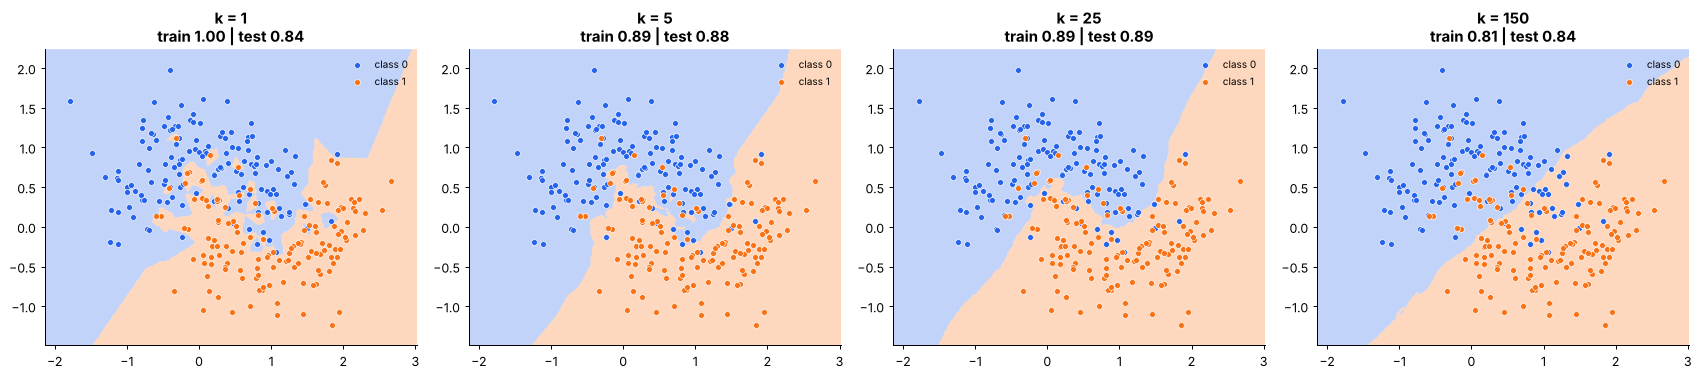

In [4]:
Xm, ym = make_moons(400, noise=0.35, random_state=3)
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(Xm, ym, test_size=0.3, stratify=ym, random_state=RANDOM_STATE)
fig, axes = plt.subplots(1, 4, figsize=(19, 4.3))
for ax, k in zip(axes, [1, 5, 25, 150]):
    m = KNeighborsClassifier(k).fit(Xm_tr, ym_tr)
    plot_decision_boundary(m, Xm_tr, ym_tr, ax=ax, title=f"k = {k}\ntrain {m.score(Xm_tr, ym_tr):.2f} | test {m.score(Xm_te, ym_te):.2f}")
plt.tight_layout(); plt.show()

- **k = 1:** perfect training accuracy, islands around every stray point: memorisation.
- **k = 5–25:** the sweet spot; smooth boundary that follows the moons.
- **k = 150 (≈ ½ the data):** the boundary degenerates toward a straight line / the majority class.

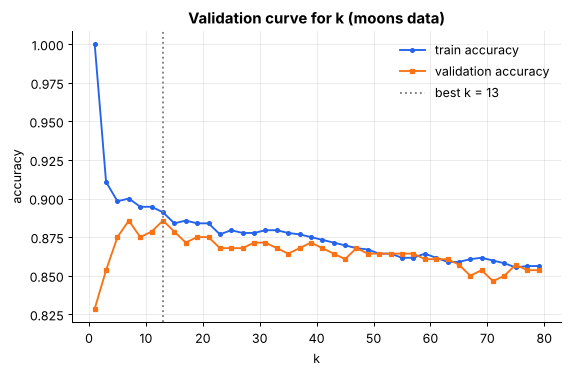

In [5]:
ks = np.arange(1, 80, 2); skf = StratifiedKFold(5, shuffle=True, random_state=0)
tr, va = validation_curve(KNeighborsClassifier(), Xm_tr, ym_tr, param_name="n_neighbors", param_range=ks, cv=skf, scoring="accuracy")
plt.plot(ks, tr.mean(1), "o-", ms=3, label="train accuracy"); plt.plot(ks, va.mean(1), "s-", ms=3, label="validation accuracy")
plt.axvline(ks[va.mean(1).argmax()], color="gray", ls=":", label=f"best k = {ks[va.mean(1).argmax()]}"); plt.xlabel("k"); plt.ylabel("accuracy"); plt.legend(); plt.title("Validation curve for k (moons data)"); plt.show()

---
## ⚖️ 5. Scaling and distance metrics

Breast-cancer measurements live on wildly different scales (area ≈ 500–2500, smoothness ≈ 0.05–0.16). Without scaling, *area* single-handedly decides who is a neighbour.

feature scale range (std): 0.0027 to 566.2
KNN on RAW features   : test accuracy = 0.930
KNN on SCALED features: test accuracy = 0.965


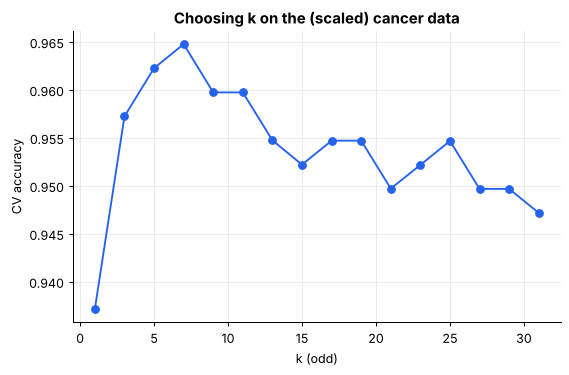

best k by CV: 7 -> 0.965


In [6]:
print("feature scale range (std):", Xb_tr.std(axis=0).min().round(4), "to", Xb_tr.std(axis=0).max().round(1))
raw = KNeighborsClassifier(5).fit(Xb_tr, yb_tr); scl = KNeighborsClassifier(5).fit(Ztr, yb_tr)
print(f"KNN on RAW features   : test accuracy = {raw.score(Xb_te, yb_te):.3f}")
print(f"KNN on SCALED features: test accuracy = {scl.score(Zte, yb_te):.3f}")
cvk = {k: cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(k)), Xb_tr, yb_tr, cv=skf).mean() for k in range(1, 32, 2)}
plt.plot(list(cvk), list(cvk.values()), "o-"); plt.xlabel("k (odd)"); plt.ylabel("CV accuracy"); plt.title("Choosing k on the (scaled) cancer data"); plt.show()
print("best k by CV:", max(cvk, key=cvk.get), "->", round(max(cvk.values()), 3))

**Distance metrics** change what 'similar' means. Common choices: **Euclidean** (L2), **Manhattan** (L1: more robust when a few coordinates differ a lot), and **cosine** (compares the *direction* of vectors and ignores their length; popular for text and embeddings). We'll compare them on digits next.

---
## ✍️ 6. Digits: where KNN shines

scikit-learn ships a classic: 1 797 handwritten digits, each an 8×8 grey-scale image (64 features), 10 classes. Similar-looking digits have similar pixels, so *nearest neighbour* is a natural fit.

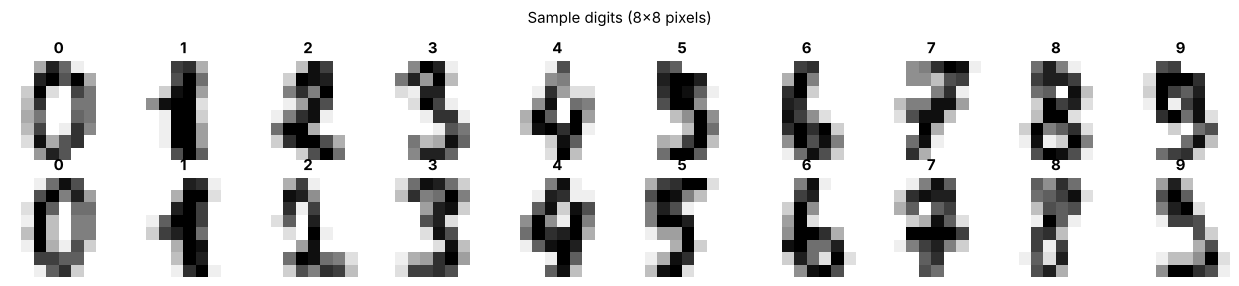

KNN (k=3) test accuracy on digits: 0.987   (a 10-class problem; random guessing = 0.10)


In [7]:
dg = load_digits()
fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for i, ax in enumerate(axes.ravel()): ax.imshow(dg.images[i], cmap="gray_r"); ax.set_title(dg.target[i]); ax.axis("off")
plt.suptitle("Sample digits (8×8 pixels)"); plt.tight_layout(); plt.show()
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(dg.data, dg.target, test_size=0.3, stratify=dg.target, random_state=RANDOM_STATE)
knn_d = KNeighborsClassifier(3).fit(Xd_tr, yd_tr)
print(f"KNN (k=3) test accuracy on digits: {knn_d.score(Xd_te, yd_te):.3f}   (a 10-class problem; random guessing = 0.10)")

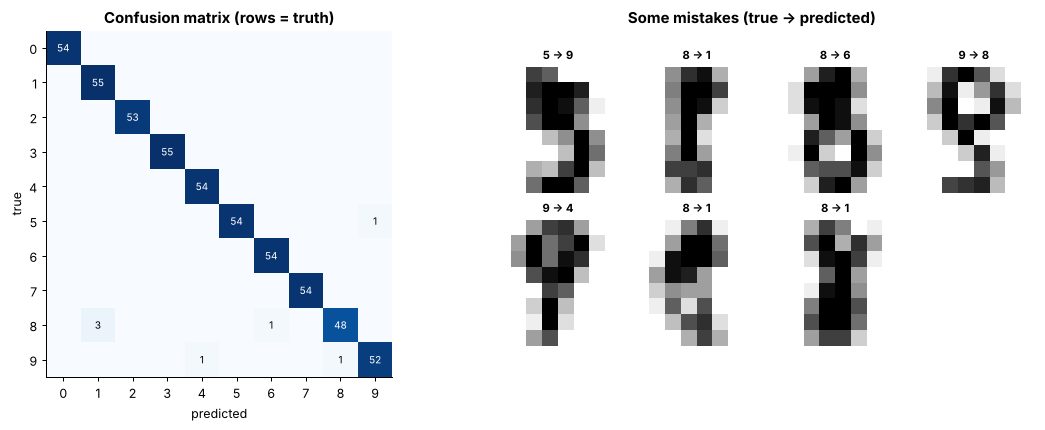

Metric comparison on digits (k=3):
  euclidean  test acc = 0.987
  manhattan  test acc = 0.985
  cosine     test acc = 0.987


In [8]:
pred_d = knn_d.predict(Xd_te); cm = confusion_matrix(yd_te, pred_d)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
im = axes[0].imshow(cm, cmap="Blues"); axes[0].set_title("Confusion matrix (rows = truth)"); axes[0].set_xlabel("predicted"); axes[0].set_ylabel("true"); axes[0].set_xticks(range(10)); axes[0].set_yticks(range(10)); axes[0].grid(False)
for i in range(10):
    for j in range(10):
        if cm[i, j]: axes[0].text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=8)
wrong = np.where(pred_d != yd_te)[0][:8]
axes[1].axis("off"); axes[1].set_title("Some mistakes (true → predicted)")
for n, i in enumerate(wrong):
    ax_ = fig.add_axes([0.52 + (n % 4) * 0.11, 0.52 - (n // 4) * 0.34, 0.1, 0.28]); ax_.imshow(Xd_te[i].reshape(8, 8), cmap="gray_r"); ax_.set_title(f"{yd_te[i]} → {pred_d[i]}", fontsize=9); ax_.axis("off")
plt.show()
print("Metric comparison on digits (k=3):")
for met in ["euclidean", "manhattan", "cosine"]:
    print(f"  {met:<10} test acc = {KNeighborsClassifier(3, metric=met, algorithm='brute').fit(Xd_tr, yd_tr).score(Xd_te, yd_te):.3f}")

> 🔑 **Key idea.**
>
> Almost 99 % with *no training at all* by KNN is hard to beat when (a) similar examples really do share labels, and (b) there's plenty of labelled data nearby. The few mistakes are exactly the ones a human would find ambiguous (a sloppy 8 that looks like a 1). The price: every prediction compares the image with *all* 1 257 stored examples.

---
## 🚨 7. Imbalanced data: where KNN struggles

A vote favours whoever is most numerous. With 2 % positives, a rare class rarely wins a neighbourhood vote, and the bigger k, the worse it gets.

In [9]:
Xi, yi = make_classification(n_samples=5000, n_features=10, n_informative=5, weights=[0.98, 0.02], flip_y=0.01, class_sep=1.2, random_state=1)
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(Xi, yi, test_size=0.3, stratify=yi, random_state=RANDOM_STATE)
rows = []
for k in [1, 5, 15, 25]:
    m = make_pipeline(StandardScaler(), KNeighborsClassifier(k)).fit(Xi_tr, yi_tr); pr = m.predict_proba(Xi_te)[:, 1]
    for tau in [0.5, 0.2]:
        p = (pr >= tau).astype(int); rows.append({"k": k, "threshold": tau, "recall": recall_score(yi_te, p), "precision": precision_score(yi_te, p, zero_division=0), "PR-AUC": average_precision_score(yi_te, pr)})
display(pd.DataFrame(rows).round(3))

,k,threshold,recall,precision,PR-AUC
0,1,0.5,0.395,0.714,0.297
1,1,0.2,0.395,0.714,0.297
2,5,0.5,0.211,1.000,0.387
3,5,0.2,0.553,0.318,0.387
4,15,0.5,0.026,1.000,0.432
5,15,0.2,0.316,0.923,0.432
6,25,0.5,0.026,1.000,0.501
7,25,0.2,0.211,0.889,0.501


At the default threshold 0.5 a positive needs a **majority** of its k neighbours to be positive: nearly impossible when 98 % of all points are negative. Recall collapses as k grows. Fixes:
1. **Lower the threshold** (to ≈ the base rate region): the table shows recall jumping at τ = 0.2.
2. Use `weights='distance'` so very close positives count more.
3. Resample/undersample the majority class, or choose a smaller k.
4. Prefer a model that handles weights natively (trees, logistic regression with `class_weight`).

---
## 🌌 8. Curse of dimensionality, speed and probabilities

**Irrelevant features** poison distances (Lesson 07). Let's append noise columns to the standardised cancer data and compare three classifiers:

,KNN (k=7),Logistic regression,Random forest
noise features,,,
0,0.965,0.971,0.965
10,0.959,0.971,0.971
30,0.959,0.977,0.959
90,0.906,0.947,0.947


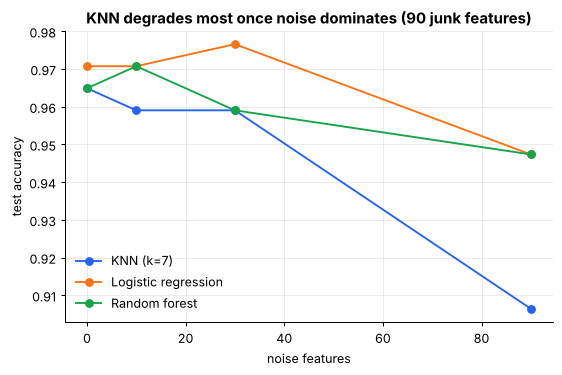

In [10]:
rng = np.random.default_rng(0); rows = []
for n_noise in [0, 10, 30, 90]:
    A = np.c_[Ztr, rng.normal(size=(len(Ztr), n_noise))]; B = np.c_[Zte, rng.normal(size=(len(Zte), n_noise))]
    rows.append({"noise features": n_noise, "KNN (k=7)": KNeighborsClassifier(7).fit(A, yb_tr).score(B, yb_te),
                 "Logistic regression": LogisticRegression(max_iter=3000).fit(A, yb_tr).score(B, yb_te),
                 "Random forest": RandomForestClassifier(150, random_state=0, n_jobs=-1).fit(A, yb_tr).score(B, yb_te)})
res = pd.DataFrame(rows).set_index("noise features"); display(res.round(3)); res.plot(marker="o"); plt.ylabel("test accuracy"); plt.title("KNN degrades most once noise dominates (90 junk features)"); plt.show()

**Speed.** KNN stores everything (memory O(n·p)) and each prediction costs O(n·p) by brute force: fine for thousands of rows, painful for millions. kd-/ball-trees help in low dimensions; approximate-nearest-neighbour libraries (FAISS, Annoy) handle huge data.

**Probabilities.** KNN's probability is a vote share, so it can only take values $0, \frac1k, \dots, 1$: coarse for small k. Larger k or distance weighting gives finer values.

In [11]:
for k in [1, 5, 25]:
    m = KNeighborsClassifier(k).fit(Ztr, yb_tr); pr = m.predict_proba(Zte)[:, 1]
    print(f"k={k:<3} distinct probability values on the test set: {len(np.unique(pr.round(6))):>3}  (max possible: {k + 1})")

k=1   distinct probability values on the test set:   2  (max possible: 2)
k=5   distinct probability values on the test set:   6  (max possible: 6)
k=25  distinct probability values on the test set:  24  (max possible: 26)


---
## 📋 9. Cheat-sheet: the full profile of KNN Classification

| Question | Answer |
|---|---|
| **Underlying concept** | Classify by a (weighted) majority vote among the k most similar training points. |
| **How it works** | Store all training data; for each query compute distances, take the k smallest, vote (vote shares = probabilities). |
| **Mathematical foundation** | Non-parametric density/probability estimation; Minkowski/cosine distances; Cover–Hart bound (1-NN error ≤ 2× Bayes); consistency as k→∞, k/n→0. |
| **Important parameters** | `n_neighbors` (k), `weights` (uniform/distance), `metric`/`p`, `algorithm` (brute/kd_tree/ball_tree/auto), `leaf_size`. Scale features! |
| **Advantages** | Trivial to understand and implement; no training; flexible non-linear boundaries; naturally multi-class; strong on local-structure problems (digits, recommendations); explains itself with neighbours. |
| **Disadvantages** | Slow/memory-hungry prediction; needs scaling; hurt by irrelevant & high-dimensional features; sensitive to class imbalance and to k; no learned model or feature importance. |
| **Complexity** | Fit O(1) (or O(n log n) for tree indexes); predict O(n·p) per query brute force (≈O(log n) with trees in low dimensions); memory O(n·p). |
| **Use cases** | Small/medium datasets with meaningful distances: digits/image patches, recommenders, anomaly detection, geospatial lookups, quick baselines. |
| **Limitations** | Doesn't scale to big data without approximate indexes; poor with many noisy features or mixed categorical data without a custom metric; majority-class bias. |

---
## 🧪 10. Worked examples

### Worked Example 1: Weighted vs unweighted

Query with 5 nearest neighbours: distances $[0.5, 1, 1, 2, 2]$ and classes $[B, A, A, B, B]$.
*Unweighted:* B has 3 votes, A has 2 → **B**. *Inverse-distance weights* $[2, 1, 1, 0.5, 0.5]$: A total $=1+1=2$; B total $=2+0.5+0.5=3$ → still **B** (the closest point is B). Change the closest point to A (classes $[A,A,A,B,B]$): unweighted A=3 vs B=2 → A; weighted A $=2+1+1=4$ vs B $=1$ → A with a much stronger margin (80 % vs 60 %).

In [12]:
d_ = np.array([0.5, 1, 1, 2, 2]); w_ = 1 / d_
for c_ in [np.array(["B", "A", "A", "B", "B"]), np.array(["A", "A", "A", "B", "B"])]:
    print(list(c_), "-> weighted shares", {c: round(float(w_[c_ == c].sum() / w_.sum()), 3) for c in ["A", "B"]}, "| unweighted", {c: round(float((c_ == c).mean()), 3) for c in ["A", "B"]})

[np.str_('B'), np.str_('A'), np.str_('A'), np.str_('B'), np.str_('B')] -> weighted shares {'A': 0.4, 'B': 0.6} | unweighted {'A': 0.4, 'B': 0.6}
[np.str_('A'), np.str_('A'), np.str_('A'), np.str_('B'), np.str_('B')] -> weighted shares {'A': 0.8, 'B': 0.2} | unweighted {'A': 0.6, 'B': 0.4}


### Worked Example 2: Why the threshold matters for KNN on rare classes

A KNN with k = 10 has 2 positive neighbours out of 10 for a query: $\hat P(+)=0.2$. At the default threshold 0.5 → predict negative. If the positive class is 2 % of the population, a local share of 20 % is **ten times the base rate**: a strong signal that the default threshold ignores. Setting $\tau=0.15$ flags it.

---
### 🧩 Problem 1: Classify by hand (in code)  ⭐

Write `knn_classify(xq, X, y, k, weighted=False)` (Euclidean distance, no scikit-learn) returning `(label, vote_shares_dict)` where the dict maps each class to its (weighted) vote share. Use the lesson's `pts`, `lab` and `q = [3, 3]`: store `res3 = knn_classify(q, pts, lab, 3)` and `res5 = knn_classify(q, pts, lab, 5)` and `res5w = knn_classify(q, pts, lab, 5, weighted=True)`.

In [13]:
# ✅ SOLUTION
def knn_classify(xq, X, y, k, weighted=False):
    d = np.sqrt(((X - xq) ** 2).sum(axis=1)); idx = np.argsort(d)[:k]
    w = 1 / np.maximum(d[idx], 1e-12) if weighted else np.ones(k)
    shares = {str(c): float(w[y[idx] == c].sum() / w.sum()) for c in np.unique(y)}
    return max(shares, key=shares.get), shares

res3 = knn_classify(q, pts, lab, 3); res5 = knn_classify(q, pts, lab, 5); res5w = knn_classify(q, pts, lab, 5, weighted=True)
print(res3, res5, res5w)

('A', {'A': 0.6666666666666666, 'B': 0.3333333333333333}) ('B', {'A': 0.4, 'B': 0.6}) ('B', {'A': 0.45331335270792505, 'B': 0.546686647292075})


**Why this works.** The prediction flips between k = 3 and k = 5 because the 4th and 5th nearest points are class B: the very sensitivity to k that cross-validation is for.

In [14]:
check("k=3 -> A (2 of 3 neighbours)", lambda: res3[0] == "A" and abs(res3[1]["A"] - 2 / 3) < 1e-9)
check("k=5 -> B (3 of 5 neighbours)", lambda: res5[0] == "B" and abs(res5[1]["B"] - 0.6) < 1e-9)
check("shares sum to 1", lambda: abs(sum(res5w[1].values()) - 1) < 1e-9)

✅  k=3 -> A (2 of 3 neighbours)
✅  k=5 -> B (3 of 5 neighbours)
✅  shares sum to 1


---
### 🧩 Problem 2: Choose k by cross-validation  ⭐

Using the scaled cancer data `Ztr, yb_tr, Zte, yb_te`: evaluate odd `k` from 1 to 31 with `StratifiedKFold(5, shuffle=True, random_state=0)` accuracy on `Ztr` → dict `cv_acc`. Store `best_k` (highest CV accuracy; smallest k on ties) and `test_acc` for that k fit on all of `Ztr`.

In [15]:
# ✅ SOLUTION
cv_acc = {k: cross_val_score(KNeighborsClassifier(k), Ztr, yb_tr, cv=skf).mean() for k in range(1, 32, 2)}
best_k = min(k for k, v in cv_acc.items() if v == max(cv_acc.values()))
test_acc = KNeighborsClassifier(best_k).fit(Ztr, yb_tr).score(Zte, yb_te)
print(best_k, round(cv_acc[best_k], 3), round(test_acc, 3))

5 0.962 0.965


**Why this works.** k = 1 is noisy; a handful of neighbours (5–11) gives the best generalisation. (The numerical differences between k = 5, 7, 9 are tiny; within noise.)

In [16]:
check("16 odd values of k tested", lambda: len(cv_acc) == 16)
check("k=1 is not the best", lambda: best_k != 1)
check("test accuracy > 0.94", lambda: test_acc > 0.94)

✅  16 odd values of k tested
✅  k=1 is not the best
✅  test accuracy > 0.94


---
### 🧩 Problem 3: Price of ignoring scale  ⭐

Compute `acc_raw` and `acc_scaled`: test accuracy of `KNeighborsClassifier(5)` on the **raw** cancer features (`Xb_tr`/`Xb_te`) and on the **scaled** ones (`Ztr`/`Zte`). Also find `dominant` = the name (from `bc.feature_names`) of the raw feature with the largest standard deviation in `Xb_tr`: the one that dominates raw distances.

In [17]:
# ✅ SOLUTION
acc_raw = KNeighborsClassifier(5).fit(Xb_tr, yb_tr).score(Xb_te, yb_te); acc_scaled = KNeighborsClassifier(5).fit(Ztr, yb_tr).score(Zte, yb_te)
dominant = str(bc.feature_names[Xb_tr.std(axis=0).argmax()])
print(acc_raw, acc_scaled, dominant)

0.9298245614035088 0.9649122807017544 worst area


**Why this works.** 'worst area' reaches the thousands, so it essentially *is* the distance between two tumours in raw space: the other 29 features are a rounding error.

In [18]:
check("scaling improves accuracy by at least 0.02", lambda: acc_scaled - acc_raw >= 0.02)
check("the dominant raw feature is an area measurement", lambda: "area" in dominant)

✅  scaling improves accuracy by at least 0.02
✅  the dominant raw feature is an area measurement


---
### 🧩 Problem 4: Read the digit confusions  ⭐⭐

With the lesson's `cm` (confusion matrix of the k = 3 digit classifier): set `accuracy_d` = overall accuracy computed from `cm` (trace / total), `worst_pair` = the tuple `(true_digit, predicted_digit)` of the **largest off-diagonal** entry (first one if tied), and `n_worst` = its count. Also `per_class_recall` = a length-10 array of recall for each digit (diagonal / row sum) and `hardest_digit` = the digit with the lowest recall.

In [19]:
# ✅ SOLUTION
accuracy_d = np.trace(cm) / cm.sum()
off = cm.copy(); np.fill_diagonal(off, 0); worst_pair = tuple(int(v) for v in np.unravel_index(off.argmax(), off.shape)); n_worst = int(off.max())
per_class_recall = np.diag(cm) / cm.sum(axis=1); hardest_digit = int(per_class_recall.argmin())
print(round(accuracy_d, 3), worst_pair, n_worst, per_class_recall.round(2), hardest_digit)

0.987 (8, 1) 3 [1.   1.   1.   1.   1.   0.98 1.   1.   0.92 0.96] 8


**Why this works.** Overall accuracy hides per-class differences: some digits are recognised perfectly, a couple a bit less so. Always read the confusion matrix, not just the headline number.

In [20]:
check("overall accuracy ≈ 0.987", lambda: abs(accuracy_d - knn_d.score(Xd_te, yd_te)) < 1e-9)
check("worst pair is a plausible confusion (two different digits)", lambda: worst_pair[0] != worst_pair[1])
check("per-class recall has 10 entries in [0, 1]", lambda: len(per_class_recall) == 10 and ((per_class_recall >= 0) & (per_class_recall <= 1)).all())
check("hardest digit has the minimum recall", lambda: per_class_recall[hardest_digit] == per_class_recall.min())

✅  overall accuracy ≈ 0.987
✅  worst pair is a plausible confusion (two different digits)
✅  per-class recall has 10 entries in [0, 1]
✅  hardest digit has the minimum recall


---
### 🧩 Problem 5: Rescue a rare class with the threshold  ⭐⭐

On the fraud data (`Xi_tr, yi_tr, Xi_te, yi_te`) fit `make_pipeline(StandardScaler(), KNeighborsClassifier(15))`. Using `predict_proba`, store the recall and precision at the default threshold (`rec_50`, `prec_50`) and at `τ = 0.1` (`rec_10`, `prec_10`). Set `tradeoff_ok = True` if recall went **up** and precision went **down**.

In [21]:
# ✅ SOLUTION
knn_f = make_pipeline(StandardScaler(), KNeighborsClassifier(15)).fit(Xi_tr, yi_tr); pr = knn_f.predict_proba(Xi_te)[:, 1]
p50, p10 = (pr >= 0.5).astype(int), (pr >= 0.1).astype(int)
rec_50, prec_50 = recall_score(yi_te, p50), precision_score(yi_te, p50, zero_division=0)
rec_10, prec_10 = recall_score(yi_te, p10), precision_score(yi_te, p10, zero_division=0)
tradeoff_ok = bool(rec_10 > rec_50 and prec_10 < prec_50)
print(rec_50, prec_50, rec_10, prec_10, tradeoff_ok)

0.02631578947368421 1.0 0.47368421052631576 0.5806451612903226 True


**Why this works.** With k = 15 almost no positive wins a majority vote. Treating the vote share as a *score* and thresholding at a lower value recovers most positives: at the cost of many false alarms: exactly the precision/recall trade-off of Lesson 09.

In [22]:
check("recall at τ=0.5 is poor (< 0.2)", lambda: rec_50 < 0.2)
check("lowering τ to 0.1 multiplies recall (> 0.4)", lambda: rec_10 > 0.4)
check("recall up, precision down", lambda: tradeoff_ok)

✅  recall at τ=0.5 is poor (< 0.2)
✅  lowering τ to 0.1 multiplies recall (> 0.4)
✅  recall up, precision down


---
### 🧩 Problem 6: Which distance metric wins on digits?  ⭐⭐

Fit `KNeighborsClassifier(3, metric=m, algorithm='brute')` on `Xd_tr, yd_tr` for `m` in `['euclidean', 'manhattan', 'cosine', 'chebyshev']` and store the test accuracies in `metric_acc` (dict). Set `best_metric` (highest accuracy; first in list on ties) and `spread` = max − min accuracy.

In [23]:
# ✅ SOLUTION
metric_acc = {m: KNeighborsClassifier(3, metric=m, algorithm="brute").fit(Xd_tr, yd_tr).score(Xd_te, yd_te) for m in ["euclidean", "manhattan", "cosine", "chebyshev"]}
best_metric = max(metric_acc, key=metric_acc.get); spread = max(metric_acc.values()) - min(metric_acc.values())
print({k: round(v, 3) for k, v in metric_acc.items()}, best_metric, round(spread, 3))

{'euclidean': 0.987, 'manhattan': 0.985, 'cosine': 0.987, 'chebyshev': 0.976} euclidean 0.011


**Why this works.** Euclidean, Manhattan and cosine are all excellent on pixel data; Chebyshev, which looks only at the single most-different pixel, throws away most of the information. 'Similarity' must be chosen to fit the problem.

In [24]:
check("four metrics evaluated", lambda: len(metric_acc) == 4)
check("Chebyshev is the worst metric for images", lambda: min(metric_acc, key=metric_acc.get) == "chebyshev")
check("the best metric reaches > 0.98", lambda: metric_acc[best_metric] > 0.98)

✅  four metrics evaluated
✅  Chebyshev is the worst metric for images
✅  the best metric reaches > 0.98


---
## 🧠 Check Your Understanding
Answer each question in your head (or on paper) *before* opening the answer.

**Q1.** Why choose an odd k for binary classification?

<details><summary>👀 Show answer</summary>

To avoid tied votes.

</details>

**Q2.** Why does a larger k make KNN worse on very imbalanced data?

<details><summary>👀 Show answer</summary>

A positive needs a majority of its neighbours to be positive; with few positives, larger neighbourhoods are dominated by the majority class, so almost nothing is predicted positive.

</details>

**Q3.** You doubled the number of training rows. What happens to KNN's training time and prediction time?

<details><summary>👀 Show answer</summary>

Training time stays ≈ 0 (it only stores data); prediction time per query roughly doubles (brute force).

</details>

**Q4.** Which of these would hurt KNN more: 10 irrelevant extra features, or 10 irrelevant extra *rows*? Why?

<details><summary>👀 Show answer</summary>

Extra features: every distance gets contaminated by noise dimensions. Extra rows only add (harmlessly unhelpful) candidates.

</details>

**Q5.** When is cosine distance preferable to Euclidean?

<details><summary>👀 Show answer</summary>

When the direction of the vector matters more than its magnitude: e.g. text/TF-IDF vectors or embeddings, where document length shouldn't affect similarity.

</details>

---
## 🔁 Recap

- KNN classifies by a vote among the k nearest training points; vote shares are (coarse) probabilities.
- Small k → jagged, high variance; large k → smooth, high bias; choose k (odd) by cross-validation.
- Scale your features and choose a distance that fits your data (Euclidean, Manhattan, cosine).
- Excellent on local-structure problems like digits (≈ 98.7 %), weak on imbalanced, noisy or high-dimensional data.
- No training, but memory-heavy and O(n·p) per prediction; thresholds are the cure for rare classes.

### ➡️ Up next: **Naive Bayes**
Open `14_Naive_Bayes.ipynb` when you're ready.

*You did the hard part: you thought about it, not just ran it. See you in the next one!* 🚀